# Семинар 2. Ван-дер-Поль: разбираем численное решение

На прошлой паре мы уже решили уравнение Ван-дер-Поля численно, построили $x(t)$ и фазовые траектории и увидели, что решения выходят на предельный цикл.

Сегодня продолжим с той же системой и попробуем получить из численного решения не только картинки, но и конкретные характеристики: амплитуду, период, переходный участок и зависимость поведения от $\mu$.

Рассматриваем
$$
x''-\mu(1-x^2)x'+x=0,\qquad \mu > 0,
$$
или, после замены $y=x'$,
$$
\begin{cases}
x'=y,\\
y'=\mu(1-x^2)y-x.
\end{cases}
$$

В некоторых местах сначала ответьте на вопрос, а уже потом запускайте следующую ячейку.

Численные результаты не берём «на глаз»: если в выводе указано конкретное значение, оно должно быть посчитано в notebook.

## 0. Импорт библиотек

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

## 1. Разбираем результат `solve_ivp`

Сначала ещё раз решим уже знакомую задачу:
$$
\mu=1,\qquad x(0)=0.1,\qquad y(0)=0.
$$

Перед запуском посмотрите на функцию `vdp` и ответьте:

1. Что лежит в `state`?
2. Что должна вернуть функция?
3. Сколько строк вы ожидаете увидеть в `sol.y`?

**Ответы перед запуском:**

1. В `state` лежат две текущие координаты состояния: `x` и `y=x'`.
2. Функция `vdp` должна вернуть производные этих координат: `[x', y']`.
3. В `sol.y` ожидаются две строки: одна для `x(t)`, вторая для `y(t)`.

In [2]:
def vdp(t, state, mu):
    x, y = state
    return [y, mu * (1 - x**2) * y - x]


mu = 1.0
t_eval = np.linspace(0, 60, 6001)

sol = solve_ivp(
    vdp,
    t_span=(0, 60),
    y0=[0.1, 0.0],
    t_eval=t_eval,
    args=(mu,),
    rtol=1e-8,
    atol=1e-10,
)

print("success:", sol.success)
print("sol.t.shape =", sol.t.shape)
print("sol.y.shape =", sol.y.shape)

success: True
sol.t.shape = (6001,)
sol.y.shape = (2, 6001)


### Индексация

Запустите следующую ячейку и разберите, что выдаёт каждая строка.

Особенно обратите внимание на разницу между

- `sol.y[0]`,
- `sol.y[:, 0]`,
- `sol.y[:, -1]`.

In [3]:
x = sol.y[0]
y = sol.y[1]

print("Первые 5 моментов времени:", sol.t[:5])
print("Первые 5 значений x(t):", x[:5])
print("Начальное состояние:", sol.y[:, 0])
print("Конечное состояние:", sol.y[:, -1])

Первые 5 моментов времени: [0.   0.01 0.02 0.03 0.04]
Первые 5 значений x(t): [0.1        0.09999498 0.09997987 0.09995455 0.09991894]
Начальное состояние: [0.1 0. ]
Конечное состояние: [ 1.53011576 -0.76804887]


**Разбор индексации:** `sol.y[0]` — все значения `x(t)`, `sol.y[:, 0]` — состояние `(x, y)` в первый момент времени, а `sol.y[:, -1]` — состояние в последний момент.

### Быстрая проверка

Ответьте без дополнительного кода:

1. Какой `shape` у `sol.y`?
2. Что означают две координаты этого массива?
3. Как получить $y$ в последний момент времени?
4. Почему `sol.y[0, -1]` — число, а `sol.y[0]` — массив?

## 2. Отбрасываем переходный участок

В начале решение ещё выходит на установившийся режим. Эту часть дальше не будем использовать для оценки характеристик цикла.

Оставим только точки при $t\ge 20$.

Перед запуском: что находится в `mask` — числа, индексы или логические значения?

**Ответы:**

1. `sol.y.shape = (2, len(sol.t))`: две переменные состояния и значения в каждый момент времени.
2. Первая координата массива выбирает переменную (`x` или `y`), вторая — момент времени.
3. Последнее значение `y` можно получить как `sol.y[1, -1]`.
4. `sol.y[0, -1]` выбирает один элемент, а `sol.y[0]` — всю первую строку.
5. `mask` содержит логические значения `True/False`; ими выбираются точки, где `t >= 20`.

In [4]:
mask = sol.t >= 20

print("type(mask) =", type(mask))
print("mask.shape =", mask.shape)
print("Первые элементы mask:", mask[:8])
print("Последние элементы mask:", mask[-8:])

t_ss = sol.t[mask]
x_ss = x[mask]
y_ss = y[mask]

print("Число точек после t=20:", len(t_ss))

type(mask) = <class 'numpy.ndarray'>
mask.shape = (6001,)
Первые элементы mask: [False False False False False False False False]
Последние элементы mask: [ True  True  True  True  True  True  True  True]
Число точек после t=20: 4001


### Амплитуда

Для почти симметричного периодического сигнала оценим амплитуду как
$$
A\approx\frac{\max x-\min x}{2}.
$$

После запуска вернитесь к предыдущей ячейке, замените `20` на `30` и сравните результат.

Почему после окончания переходного процесса оценка амплитуды почти не меняется?

In [5]:
amplitude = (x_ss.max() - x_ss.min()) / 2
center = (x_ss.max() + x_ss.min()) / 2

print(f"amplitude ≈ {amplitude:.6f}")
print(f"center ≈ {center:.6f}")

amplitude ≈ 2.008619
center ≈ -0.000000


In [6]:
# Сравним оценку амплитуды после t >= 20 и после t >= 30
mask30 = sol.t >= 30
x_ss30 = x[mask30]

amplitude30 = (x_ss30.max() - x_ss30.min()) / 2

print(f"A при t >= 20: {amplitude:.8f}")
print(f"A при t >= 30: {amplitude30:.8f}")
print(f"Абсолютная разница: {abs(amplitude - amplitude30):.3e}")

A при t >= 20: 2.00861928
A при t >= 30: 2.00861915
Абсолютная разница: 1.282e-07


После окончания переходного процесса траектория уже почти повторяет один и тот же устойчивый цикл, поэтому его максимумы и минимумы практически не меняются. Из-за этого оценка амплитуды при сдвиге отсечки с `t=20` на `t=30` меняется совсем мало.

### Сравните полную траекторию и установившийся цикл

Постройте **два фазовых портрета рядом**:

1. всю траекторию на интервале $0\le t\le 60$;
2. только часть при $t\ge 20$.

На первом рисунке отметьте начальную точку с помощью `plt.scatter`.

Для обоих рисунков используйте одинаковый масштаб (`axis("equal")`) и одинаковые пределы осей.

После построения ответьте:

- какая часть траектории исчезла на втором рисунке;
- какой из двух графиков лучше показывает форму предельного цикла;
- заметно ли изменится второй график, если вместо $t\ge20$ взять $t\ge30$.

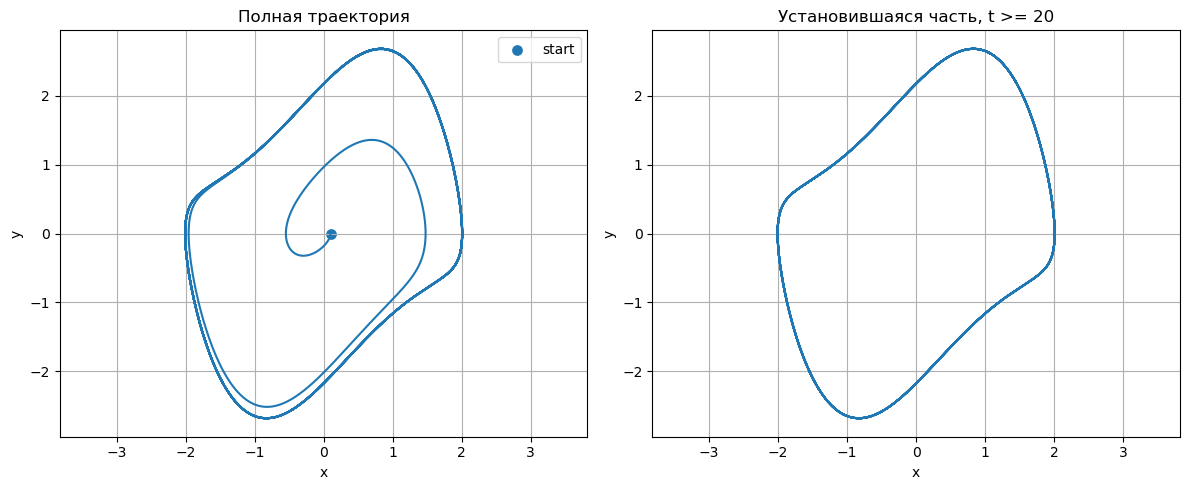

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

x_pad = 0.2
y_pad = 0.2
x_limits = (x.min() - x_pad, x.max() + x_pad)
y_limits = (y.min() - y_pad, y.max() + y_pad)

ax[0].plot(x, y)
ax[0].scatter(x[0], y[0], s=45, label="start")
ax[0].set_title("Полная траектория")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")
ax[0].legend()

ax[1].plot(x_ss, y_ss)
ax[1].set_title("Установившаяся часть, t >= 20")
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")

for a in ax:
    a.set_xlim(x_limits)
    a.set_ylim(y_limits)
    a.axis("equal")
    a.grid()

plt.tight_layout()
plt.show()

На втором рисунке исчезает начальная спираль — переход от начального состояния к устойчивому циклу. Форму самого предельного цикла лучше видно на втором графике. Если заменить `t >= 20` на `t >= 30`, форма установившегося цикла заметно не изменится.

### Центр и амплитуда на графике $x(t)$

По установившейся части решения мы уже посчитали
$$
c=\frac{x_{\max}+x_{\min}}{2},
\qquad
A=\frac{x_{\max}-x_{\min}}{2}.
$$

Теперь постройте $x(t)$ на всём интервале $0\le t\le60$ и добавьте три горизонтальные линии:
$$
x=c,\qquad x=c+A,\qquad x=c-A.
$$

Линии $c+A$ и $c-A$ должны проходить примерно по уровням установившихся максимумов и минимумов.

Ещё одной вертикальной пунктирной линией отметьте $t=20$ — момент, после которого мы оставляли решение для дальнейших расчётов.

Подпишите линии в легенде.

Ответьте:

1. почему $c$ и $A$ лучше считать после удаления переходного участка;
2. действительно ли $c+A$ и $c-A$ совпадают с уровнями установившихся максимумов и минимумов;
3. что произойдёт с оценкой амплитуды, если взять, например, $x(0)=5$ и считать `max` и `min` по всей траектории.

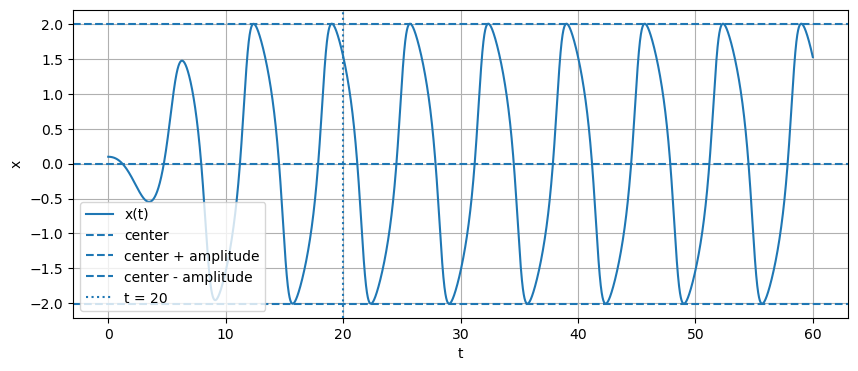

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(sol.t, x, label="x(t)")
plt.axhline(center, linestyle="--", label="center")
plt.axhline(center + amplitude, linestyle="--", label="center + amplitude")
plt.axhline(center - amplitude, linestyle="--", label="center - amplitude")
plt.axvline(20, linestyle=":", label="t = 20")
plt.xlabel("t")
plt.ylabel("x")
plt.grid()
plt.legend()
plt.show()

`center` и `amplitude` лучше считать после удаления переходного участка, потому что ранние экстремумы могут относиться не к установившемуся циклу. На графике уровни `center + amplitude` и `center - amplitude` проходят по установившимся максимумам и минимумам. Если начать, например, с `x(0)=5` и взять `max`/`min` по всей траектории, начальный выброс может завысить оценку амплитуды цикла.

## 3. Оцениваем период

Период можно примерно оценить по графику, но нам нужна численная величина.

Найдём локальные максимумы $x(t)$. Функция `find_peaks` возвращает их **индексы**.

In [9]:
peaks, _ = find_peaks(x_ss, prominence=0.5)

peak_times = t_ss[peaks]
peak_values = x_ss[peaks]

print("Последние времена максимумов:")
print(peak_times[-6:])

print("\nПоследние значения максимумов:")
print(peak_values[-6:])

Последние времена максимумов:
[25.7  32.36 39.03 45.69 52.35]

Последние значения максимумов:
[2.00861913 2.00861387 2.00860158 2.00861888 2.00861454]


Перед следующей ячейкой ответьте:

1. Что вернёт `np.diff(peak_times)`?
2. Если решение уже вышло на цикл, что должно происходить с этими разностями?

`np.diff(peak_times)` вернёт разности между соседними временами максимумов, то есть последовательные оценки периода. После выхода на устойчивый цикл эти разности должны стать почти одинаковыми.

In [10]:
periods = np.diff(peak_times)

print("Последние оценки периода:")
print(periods[-5:])

period = periods[-5:].mean()
period_std = periods[-5:].std()

print(f"Средний период T ≈ {period:.6f}")
print(f"Разброс последних периодов ≈ {period_std:.2e}")

Последние оценки периода:
[6.66 6.67 6.66 6.66]
Средний период T ≈ 6.662500
Разброс последних периодов ≈ 4.33e-03


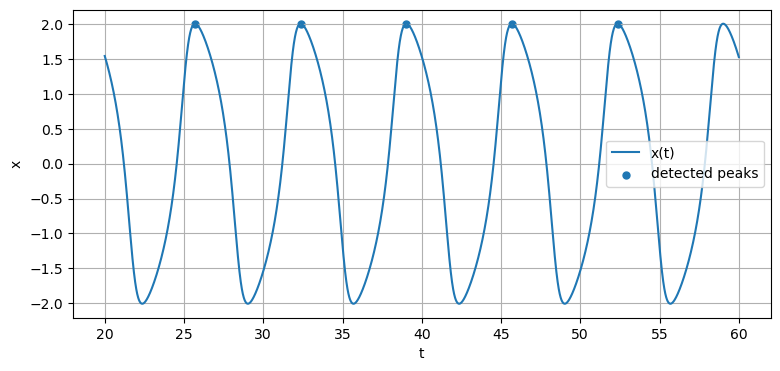

In [11]:
plt.figure(figsize=(9, 4))
plt.plot(t_ss, x_ss, label="x(t)")
plt.scatter(peak_times, peak_values, s=25, label="detected peaks")
plt.xlabel("t")
plt.ylabel("x")
plt.grid()
plt.legend()
plt.show()

### Быстрая проверка

Покажите найденные $A$ и $T$ и ответьте:

1. Почему период лучше оценивать по нескольким последним максимумам, а не по первым двум?
2. Что изменится, если сделать `t_eval` заметно плотнее?
3. Изменится ли от этого само решение дифференциального уравнения?

Период лучше оценивать по нескольким последним максимумам, потому что начало траектории ещё содержит переходный процесс, а усреднение уменьшает влияние дискретизации. Более плотный `t_eval` точнее локализует максимум на сетке и поэтому улучшает оценку периода по `find_peaks`. Само внутреннее решение `solve_ivp` от одной только плотности `t_eval` принципиально не меняется: `t_eval` задаёт точки, в которых мы просим вывести уже найденное численное решение.

## 4. Что меняется при изменении $\mu$

Теперь повторим один и тот же расчёт для нескольких значений параметра.

Напишем функцию, которая для заданного $\mu$:

- решает систему;
- отбрасывает переходный участок;
- оценивает амплитуду;
- оценивает период.

In [12]:
def cycle_stats(mu, t_end=160, t_cut=100):
    t_eval = np.linspace(0, t_end, 12001)

    sol_mu = solve_ivp(
        vdp,
        (0, t_end),
        [0.1, 0.0],
        t_eval=t_eval,
        args=(mu,),
        rtol=1e-8,
        atol=1e-10,
    )

    mask = sol_mu.t >= t_cut
    t = sol_mu.t[mask]
    x = sol_mu.y[0, mask]

    amplitude = (x.max() - x.min()) / 2

    peaks, _ = find_peaks(x, prominence=0.5)
    peak_times = t[peaks]
    period = np.diff(peak_times[-6:]).mean()

    return amplitude, period

Сначала попробуйте предсказать результат для
$$
\mu=0.2,\;0.5,\;1,\;2,\;5.
$$

Как, по-вашему, будут меняться амплитуда и период? Сначала сформулируйте предположение, потом запускайте расчёт.

**Предположение до расчёта:** амплитуда должна меняться сравнительно слабо, а период при росте `mu` должен увеличиваться заметнее. Одновременно форма цикла должна становиться всё менее похожей на почти эллиптическую.

In [13]:
mu_values = [0.2, 0.5, 1.0, 2.0, 5.0]

results = []

for mu_value in mu_values:
    A, T = cycle_stats(mu_value)
    results.append((mu_value, A, T))

for mu_value, A, T in results:
    print(f"mu={mu_value:>3}:  A≈{A:.5f},  T≈{T:.5f}")

mu=0.2:  A≈2.00041,  T≈6.29867
mu=0.5:  A≈2.00249,  T≈6.38133
mu=1.0:  A≈2.00862,  T≈6.66133
mu=2.0:  A≈2.01989,  T≈7.62933
mu=5.0:  A≈2.02151,  T≈11.61333


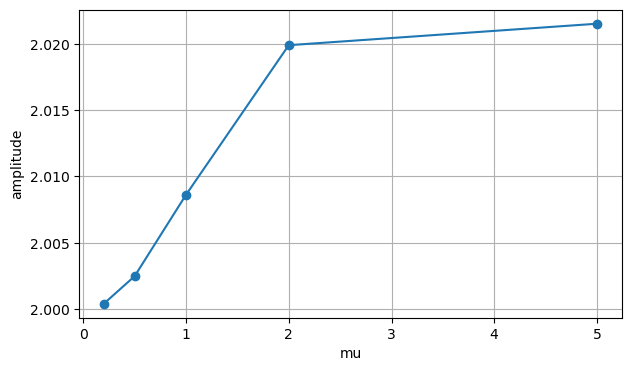

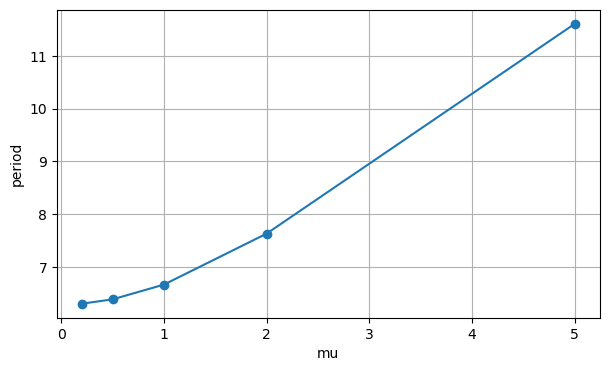

In [14]:
results_array = np.array(results)

plt.figure(figsize=(7, 4))
plt.plot(results_array[:, 0], results_array[:, 1], "o-")
plt.xlabel("mu")
plt.ylabel("amplitude")
plt.grid()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(results_array[:, 0], results_array[:, 2], "o-")
plt.xlabel("mu")
plt.ylabel("period")
plt.grid()
plt.show()

## 5. Как меняется форма предельного цикла

По графикам $A(\mu)$ и $T(\mu)$ видно, как меняются две численные характеристики, но не видно самой формы цикла.

Построим установившиеся фазовые траектории для нескольких значений $\mu$ на одном рисунке.

Перед запуском подумайте: при росте $\mu$ цикл просто увеличивается или в первую очередь меняется его форма?

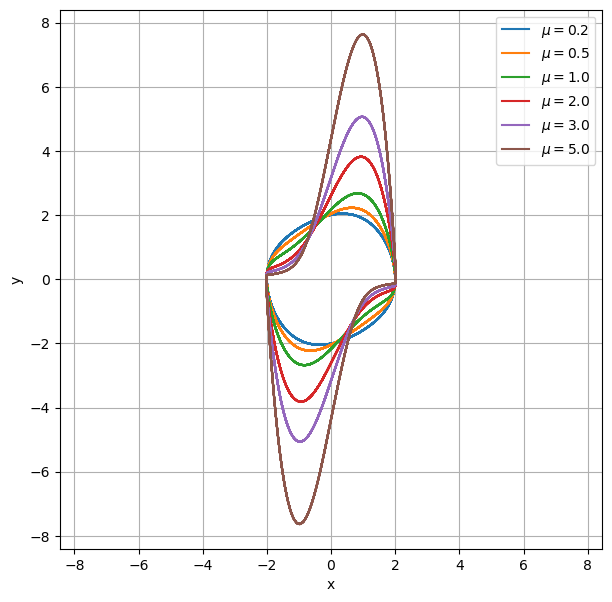

In [15]:
def settled_cycle(mu, t_end=200, t_cut=120):
    t_eval = np.linspace(0, t_end, 15001)

    sol_mu = solve_ivp(
        vdp,
        (0, t_end),
        [0.1, 0.0],
        t_eval=t_eval,
        args=(mu,),
        rtol=1e-8,
        atol=1e-10,
    )

    mask = sol_mu.t >= t_cut
    return sol_mu.y[0, mask], sol_mu.y[1, mask]


mu_for_phase_plot = [0.2, 0.5, 1.0, 2.0, 3.0, 5.0]

plt.figure(figsize=(7, 7))

for mu_value in mu_for_phase_plot:
    x_cycle, y_cycle = settled_cycle(mu_value)
    plt.plot(x_cycle, y_cycle, label=fr"$\mu={mu_value}$")

plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

### В конце пары

1. Добавьте в список `mu = 3.0` и перестройте рисунок.
2. Что меняется заметнее: максимальное значение $|x|$ или форма фазовой кривой?
3. Почему перед построением цикла мы отбрасываем начальный участок траектории?
4. Зачем здесь понадобилась отдельная функция `settled_cycle`?

Если останется время, замените начальное условие `[0.1, 0.0]` на `[3.0, 0.0]` и сравните установившиеся циклы.

---

## Что из Python здесь использовалось

За пару встретились:

- индексация NumPy-массивов;
- `shape` и булевы маски;
- `max`, `min`, `np.diff`;
- поиск пиков;
- функции;
- цикл по значениям параметра;
- Matplotlib для сравнения нескольких расчётов.

Все эти вещи дальше будут регулярно встречаться в задачах с численным решением ОДУ и оптимизацией.

**Ответы:** заметнее меняется форма фазовой кривой, а диапазон `x` — значительно слабее. Начальный участок отбрасывается, чтобы не смешивать переходный процесс с установившимся циклом. Функция `settled_cycle` нужна, чтобы один раз описать повторяющийся расчёт и затем применять его для разных `mu` без копирования одинакового кода.

# Домашняя работа — срок 2 недели

Домашку делайте в этом же notebook: допишите ячейки ниже, используя функции и код, которые уже есть выше.

Не делайте отдельный кусок кода для каждого значения $\mu$ или начального условия. Если одно и то же действие повторяется, используйте цикл или функцию.

## 1. Амплитуда и период как функции $\mu$

Возьмите не менее **20 значений**
$$
\mu\in[0.2,5].
$$

Для каждого значения найдите:

- амплитуду $A(\mu)$;
- период $T(\mu)$.

Постройте графики
$$
A(\mu), \qquad T(\mu).
$$

После графиков ответьте:

1. какая из двух величин меняется с ростом $\mu$ сильнее;
2. монотонны ли полученные зависимости;
3. есть ли диапазон $\mu$, где характер изменения особенно заметен.

Все значения должны считаться кодом.

    mu        A(mu)        T(mu)
  0.20     2.000413     6.298667
  0.40     2.001615     6.346667
  0.60     2.003510     6.421333
  0.80     2.005915     6.530667
  1.00     2.008619     6.661333
  1.20     2.011389     6.821333
  1.40     2.014001     7.000000
  1.60     2.016350     7.197333
  1.80     2.018314     7.408000
  2.00     2.019891     7.629333
  2.20     2.021105     7.861333
  2.40     2.022005     8.101333
  2.60     2.022640     8.349333
  2.80     2.023059     8.602667
  3.00     2.023302     8.858667
  3.20     2.023411     9.120000
  3.40     2.023409     9.386667
  3.60     2.023321     9.658667
  3.80     2.023166     9.928000
  4.00     2.022962    10.203333
  4.20     2.022713    10.483333
  4.40     2.022440    10.762667
  4.60     2.022145    11.040000
  4.80     2.021827    11.326667
  5.00     2.021507    11.613333


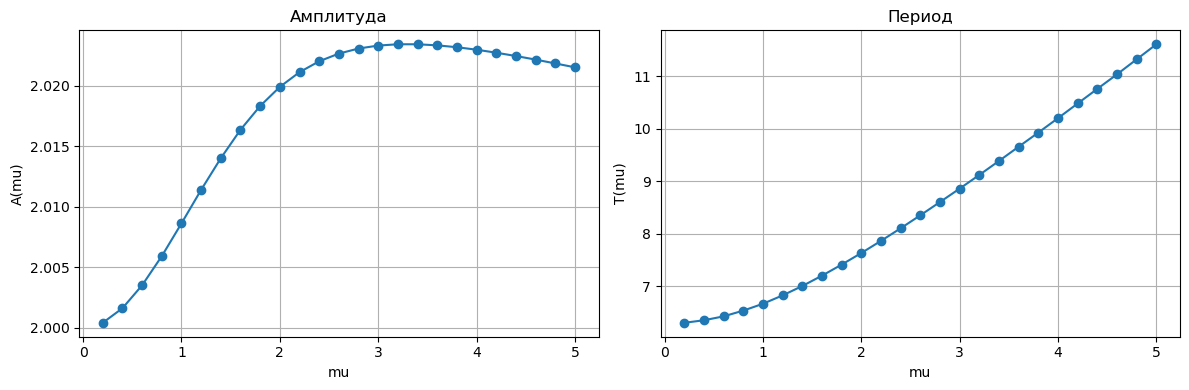

Изменение амплитуды на сетке: 0.021094
Изменение периода на сетке: 5.314667
Амплитуда монотонна на выбранной сетке: False
Период монотонен на выбранной сетке: True


In [16]:
# Задание 1. Амплитуда и период как функции mu
mu_grid = np.linspace(0.2, 5.0, 25)
A_values = []
T_values = []

for mu_value in mu_grid:
    A, T = cycle_stats(mu_value)
    A_values.append(A)
    T_values.append(T)

A_values = np.array(A_values)
T_values = np.array(T_values)

print(f"{'mu':>6} {'A(mu)':>12} {'T(mu)':>12}")
for mu_value, A, T in zip(mu_grid, A_values, T_values):
    print(f"{mu_value:6.2f} {A:12.6f} {T:12.6f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(mu_grid, A_values, "o-")
ax[0].set_xlabel("mu")
ax[0].set_ylabel("A(mu)")
ax[0].set_title("Амплитуда")
ax[0].grid()

ax[1].plot(mu_grid, T_values, "o-")
ax[1].set_xlabel("mu")
ax[1].set_ylabel("T(mu)")
ax[1].set_title("Период")
ax[1].grid()

plt.tight_layout()
plt.show()

amp_change = A_values[-1] - A_values[0]
period_change = T_values[-1] - T_values[0]
amp_monotone = np.all(np.diff(A_values) >= 0) or np.all(np.diff(A_values) <= 0)
period_monotone = np.all(np.diff(T_values) >= 0) or np.all(np.diff(T_values) <= 0)

print(f"Изменение амплитуды на сетке: {amp_change:.6f}")
print(f"Изменение периода на сетке: {period_change:.6f}")
print("Амплитуда монотонна на выбранной сетке:", amp_monotone)
print("Период монотонен на выбранной сетке:", period_monotone)

**Вывод по заданию 1.** Амплитуда почти не меняется: примерно от 2.00 до 2.02. Сначала она немного растёт, а после `mu≈3.2` чуть уменьшается, поэтому строго монотонной зависимости нет. Период меняется намного сильнее — примерно с 6.30 до 11.61, и с ростом `mu` он увеличивается.

## 2. Форма предельного цикла при разных $\mu$

На одном фазовом рисунке постройте установившиеся циклы для
$$
\mu=0.2,\quad 0.5,\quad 1,\quad 2,\quad 3,\quad 5.
$$

Используйте `plt.axis("equal")`.

После рисунка ответьте:

1. сильно ли меняется максимальное значение $|x|$;
2. как меняется форма цикла;
3. что видно на фазовом рисунке, чего не видно на графиках $A(\mu)$ и $T(\mu)$.

Затем отдельно для $\mu=0.2$ и $\mu=5$ постройте $x(t)$ на нескольких последних периодах и сравните вид временного сигнала с фазовым портретом.

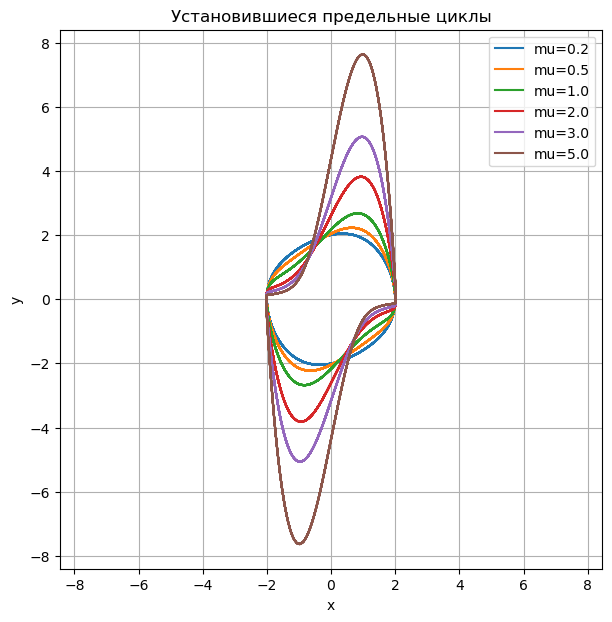

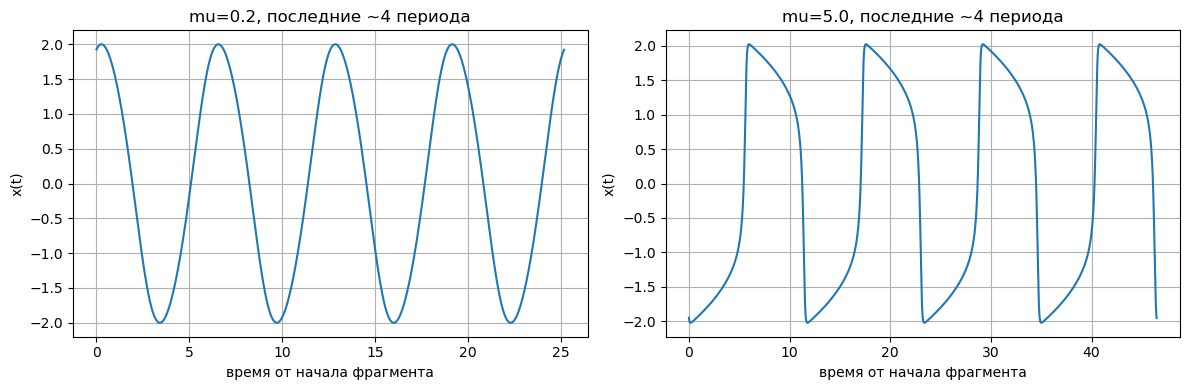

In [17]:
# Задание 2. Форма предельного цикла
mu_phase = [0.2, 0.5, 1.0, 2.0, 3.0, 5.0]

plt.figure(figsize=(7, 7))
for mu_value in mu_phase:
    x_cycle, y_cycle = settled_cycle(mu_value)
    plt.plot(x_cycle, y_cycle, label=f"mu={mu_value}")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Установившиеся предельные циклы")
plt.axis("equal")
plt.grid()
plt.legend()
plt.show()

# Несколько последних периодов x(t) для mu=0.2 и mu=5
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for a, mu_value in zip(ax, [0.2, 5.0]):
    A, T = cycle_stats(mu_value)

    t_eval_local = np.linspace(0, 220, 22001)
    sol_local = solve_ivp(
        vdp,
        (0, 220),
        [0.1, 0.0],
        t_eval=t_eval_local,
        args=(mu_value,),
        rtol=1e-8,
        atol=1e-10,
    )

    t_start = 220 - 4 * T
    mask_local = sol_local.t >= t_start

    t_plot = sol_local.t[mask_local]
    x_plot = sol_local.y[0, mask_local]

    a.plot(t_plot - t_plot[0], x_plot)
    a.set_title(f"mu={mu_value}, последние ~4 периода")
    a.set_xlabel("время от начала фрагмента")
    a.set_ylabel("x(t)")
    a.grid()

plt.tight_layout()
plt.show()

**Вывод по заданию 2.** Максимальное `|x|` почти одинаковое, но форма цикла заметно меняется. При маленьком `mu` движение более плавное, а при большом появляются медленные участки и быстрые переходы. Поэтому по фазовому портрету видно то, чего не видно только по амплитуде и периоду.

## 3. Как быстро решение выходит на цикл

Возьмите $\mu=1$ и начальные условия
$$
(0.1,0),\qquad (1,0),\qquad (3,0),\qquad (4,2).
$$

Для каждого решения найдите последовательность положительных максимумов $x(t)$ с помощью `find_peaks`.

Постройте один график:

- по горизонтальной оси — номер максимума;
- по вертикальной — его значение.

На рисунке должны быть четыре кривые.

За установившееся значение для каждой траектории возьмите среднее последних пяти максимумов. Найдите первый максимум, после которого все следующие отличаются от этого значения менее чем на **1%**.

Ответьте:

1. одинаково ли быстро разные начальные условия выходят на цикл;
2. зависит ли сам установившийся цикл от начального условия;
3. почему одного фазового портрета недостаточно, чтобы сравнить скорость выхода на цикл.

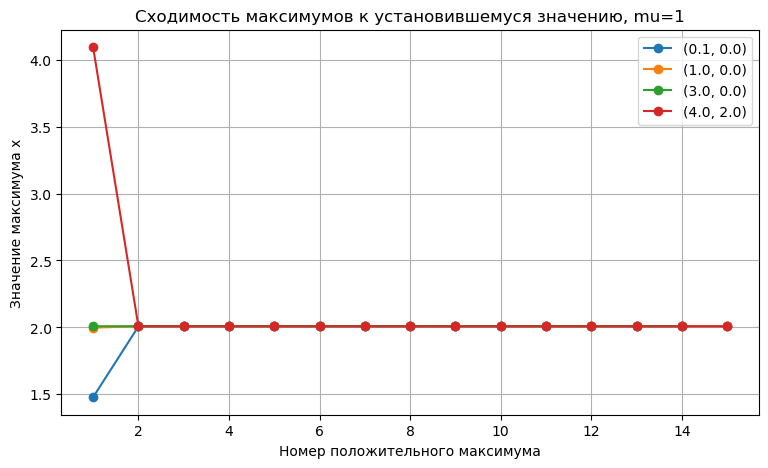

     Начальное условие   Уст. максимум   Первый max <1%  Всего max
            (0.1, 0.0)      2.00861772                2         15
            (1.0, 0.0)      2.00861806                1         15
            (3.0, 0.0)      2.00861823                1         14
            (4.0, 2.0)      2.00861767                2         15


In [18]:
# Задание 3. Как быстро решение выходит на цикл
initial_conditions = [
    (0.1, 0.0),
    (1.0, 0.0),
    (3.0, 0.0),
    (4.0, 2.0),
]

transient_rows = []

plt.figure(figsize=(9, 5))

for x0, y0 in initial_conditions:
    t_eval_local = np.linspace(0, 100, 20001)

    sol_local = solve_ivp(
        vdp,
        (0, 100),
        [x0, y0],
        t_eval=t_eval_local,
        args=(1.0,),
        rtol=1e-8,
        atol=1e-10,
    )

    x_local = sol_local.y[0]
    peaks_local, _ = find_peaks(x_local, prominence=0.05)
    peak_values_local = x_local[peaks_local]

    settled_value = peak_values_local[-5:].mean()
    rel_errors = np.abs(peak_values_local - settled_value) / abs(settled_value)

    first_good = None
    for k in range(len(rel_errors)):
        if np.all(rel_errors[k:] < 0.01):
            first_good = k + 1
            break

    transient_rows.append(
        (f"({x0}, {y0})", settled_value, first_good, len(peak_values_local))
    )

    plt.plot(
        np.arange(1, len(peak_values_local) + 1),
        peak_values_local,
        "o-",
        label=f"({x0}, {y0})",
    )

plt.xlabel("Номер положительного максимума")
plt.ylabel("Значение максимума x")
plt.title("Сходимость максимумов к установившемуся значению, mu=1")
plt.grid()
plt.legend()
plt.show()

print(
    f"{'Начальное условие':>22} "
    f"{'Уст. максимум':>15} "
    f"{'Первый max <1%':>16} "
    f"{'Всего max':>10}"
)

for cond, settled, first_good, count in transient_rows:
    print(
        f"{cond:>22} "
        f"{settled:15.8f} "
        f"{str(first_good):>16} "
        f"{count:10d}"
    )

**Вывод по заданию 3.** Начальные условия влияют в основном на первые колебания. Для `(1, 0)` и `(3, 0)` критерий 1% выполняется уже с первого максимума, а для `(0.1, 0)` и `(4, 2)` — со второго. При этом установившийся максимум почти одинаков во всех случаях: около 2.0086. То есть к одному и тому же циклу система приходит с немного разной скоростью.

## 4. Период двумя способами

На семинаре мы оценивали период по расстоянию между соседними максимумами $x(t)$.

Теперь найдите его другим способом — по последовательным пересечениям прямой
$$
x=0
$$
в одном направлении.

В `solve_ivp` для этого есть `events`.

Подсказка:

```python
def x_zero(t, state, mu):
    return state[0]

x_zero.direction = 1
x_zero.terminal = False
```

Для
$$
\mu=0.5,\quad 1,\quad 3,\quad 5
$$
оцените период:

1. по максимумам через `find_peaks`;
2. по событиям `solve_ivp`.

В обоих случаях используйте несколько **последних** периодов после окончания переходного процесса.

Составьте таблицу с колонками

`mu`, `T_peaks`, `T_events`, `relative_difference`.

Последнюю колонку вычислите по формуле
$$
\frac{|T_{\mathrm{peaks}}-T_{\mathrm{events}}|}{|T_{\mathrm{events}}|}.
$$

Сравните результаты двух способов.

In [19]:
# Задание 4. Период двумя способами
def x_zero(t, state, mu):
    return state[0]

x_zero.direction = 1
x_zero.terminal = False


def period_two_ways(mu, t_end=220, t_cut=120):
    t_eval_local = np.linspace(0, t_end, 33001)

    sol_local = solve_ivp(
        vdp,
        (0, t_end),
        [0.1, 0.0],
        t_eval=t_eval_local,
        args=(mu,),
        events=x_zero,
        rtol=1e-9,
        atol=1e-11,
    )

    mask_local = sol_local.t >= t_cut
    t_local = sol_local.t[mask_local]
    x_local = sol_local.y[0, mask_local]

    peaks_local, _ = find_peaks(x_local, prominence=0.5)
    peak_times_local = t_local[peaks_local]
    T_peaks = np.diff(peak_times_local[-6:]).mean()

    event_times = sol_local.t_events[0]
    event_times = event_times[event_times >= t_cut]
    T_events = np.diff(event_times[-6:]).mean()

    return T_peaks, T_events


period_rows = []

for mu_value in [0.5, 1.0, 3.0, 5.0]:
    T_peaks, T_events = period_two_ways(mu_value)
    rel_diff = abs(T_peaks - T_events) / abs(T_events)
    period_rows.append((mu_value, T_peaks, T_events, rel_diff))

print(
    f"{'mu':>6} "
    f"{'T_peaks':>12} "
    f"{'T_events':>12} "
    f"{'relative_difference':>22}"
)

for mu_value, T_peaks, T_events, rel_diff in period_rows:
    print(
        f"{mu_value:6.2f} "
        f"{T_peaks:12.6f} "
        f"{T_events:12.6f} "
        f"{rel_diff:22.8e}"
    )

    mu      T_peaks     T_events    relative_difference
  0.50     6.381333     6.380676         1.03050573e-04
  1.00     6.662667     6.663287         9.30759534e-05
  3.00     8.860000     8.859095         1.02098749e-04
  5.00    11.612000    11.612231         1.98638039e-05


**Вывод по заданию 4.** Два способа дали почти одинаковый период. Разница между результатами очень маленькая — около `0.01%` или меньше. Небольшое расхождение связано с тем, что `find_peaks` ищет максимум только среди точек `t_eval`, а `events` точнее определяет момент пересечения `x=0`.

## 5. Сравнение методов `solve_ivp`

Сравните три метода:

- `"RK45"`;
- `"DOP853"`;
- `"Radau"`.

Проведите расчёты для
$$
\mu=1,\quad 5,\quad 20.
$$

Для каждого запуска сохраните:

- `sol.success`;
- `sol.nfev` — число вычислений правой части;
- период, найденный по последним пересечениям $x=0$;
- `sol.message`.

Здесь лучше использовать `events` из предыдущего пункта и не задавать плотный `t_eval`: нас интересует работа самого solver'а.

Результаты оформите в таблицу.

Ответьте:

1. какой метод требует меньше вычислений при $\mu=1$;
2. что меняется при $\mu=20$;
3. почему при большом $\mu$ задача становится труднее для некоторых методов;
4. можно ли выбирать метод интегрирования просто «по привычке».

In [20]:
# Задание 5. Сравнение методов solve_ivp
def period_from_events_for_method(mu, method, t_end=450, t_cut=220):
    sol_method = solve_ivp(
        vdp,
        (0, t_end),
        [0.1, 0.0],
        args=(mu,),
        events=x_zero,
        method=method,
        rtol=1e-7,
        atol=1e-9,
    )

    event_times = sol_method.t_events[0]
    event_times = event_times[event_times >= t_cut]

    if len(event_times) >= 2:
        period_value = np.diff(event_times[-6:]).mean()
    else:
        period_value = np.nan

    return sol_method, period_value


solver_rows = []

for mu_value in [1.0, 5.0, 20.0]:
    for method in ["RK45", "DOP853", "Radau"]:
        sol_method, T_method = period_from_events_for_method(mu_value, method)

        solver_rows.append(
            (
                mu_value,
                method,
                sol_method.success,
                sol_method.nfev,
                T_method,
                sol_method.message,
            )
        )

print(
    f"{'mu':>5} "
    f"{'method':>8} "
    f"{'success':>9} "
    f"{'nfev':>9} "
    f"{'period':>12}  message"
)

for mu_value, method, success, nfev, period_value, message in solver_rows:
    print(
        f"{mu_value:5.1f} "
        f"{method:>8} "
        f"{str(success):>9} "
        f"{nfev:9d} "
        f"{period_value:12.6f}  "
        f"{message}"
    )

for mu_value in [1.0, 5.0, 20.0]:
    rows_mu = [row for row in solver_rows if row[0] == mu_value]
    best = min(rows_mu, key=lambda row: row[3])
    print(f"mu={mu_value}: меньше всего nfev у {best[1]} ({best[3]})")

   mu   method   success      nfev       period  message
  1.0     RK45      True     45344     6.663287  The solver successfully reached the end of the integration interval.
  1.0   DOP853      True     32471     6.663287  The solver successfully reached the end of the integration interval.
  1.0    Radau      True    146131     6.663287  The solver successfully reached the end of the integration interval.
  5.0     RK45      True     69056    11.612230  The solver successfully reached the end of the integration interval.
  5.0   DOP853      True     53183    11.612231  The solver successfully reached the end of the integration interval.
  5.0    Radau      True    174246    11.612231  The solver successfully reached the end of the integration interval.
 20.0     RK45      True     76028    34.682322  The solver successfully reached the end of the integration interval.
 20.0   DOP853      True     58217    34.682323  The solver successfully reached the end of the integration interval.

**Вывод по заданию 5.** При `mu=1` меньше всего вычислений `nfev` потребовал `DOP853`: 32471. По числу `nfev` он оказался самым экономным и при `mu=5`, и при `mu=20`. При большом `mu` считать становится сложнее, потому что в движении есть и медленные, и быстрые участки. Поэтому для разных задач могут лучше подходить разные методы.

## 6. Небольшой самостоятельный эксперимент

Выберите **один** вариант.

### Вариант A. Другой диапазон параметра

Продолжите расчёты до $\mu=10$ и посмотрите, как меняются период и форма цикла. Время интегрирования подберите самостоятельно.

### Вариант B. Другие начальные условия

Возьмите не менее 10 заметно разных начальных условий при $\mu=1$ и проверьте, выходят ли решения на один и тот же цикл. Нужен какой-то численный критерий сравнения, а не только картинка.

### Вариант C. Точность вычисления периода

Для одного выбранного $\mu$ исследуйте, как оценка периода зависит от `rtol` и `atol`. Возьмите не менее пяти наборов точностей и постройте график.

В начале пункта напишите, какой вариант выбрали. В конце — короткий вывод.

        rtol         atol       period      nfev   rel.diff from tightest
     1.0e-04      1.0e-06   8.85787651     11432           1.37595077e-04
     1.0e-05      1.0e-07   8.85909153     17042           4.45725891e-07
     1.0e-06      1.0e-08   8.85909286     25016           2.94705242e-07
     1.0e-07      1.0e-09   8.85909530     36698           2.01601997e-08
     1.0e-08      1.0e-10   8.85909548     54578           0.00000000e+00


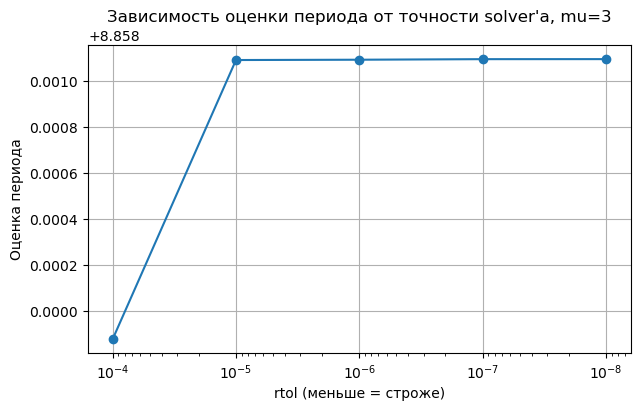

In [21]:
# Задание 6. Вариант C: влияние точности на оценку периода
mu_accuracy = 3.0

tolerances = [
    (1e-4, 1e-6),
    (1e-5, 1e-7),
    (1e-6, 1e-8),
    (1e-7, 1e-9),
    (1e-8, 1e-10),
]

accuracy_rows = []

for rtol_value, atol_value in tolerances:
    sol_acc = solve_ivp(
        vdp,
        (0, 260),
        [0.1, 0.0],
        args=(mu_accuracy,),
        events=x_zero,
        rtol=rtol_value,
        atol=atol_value,
    )

    event_times = sol_acc.t_events[0]
    event_times = event_times[event_times >= 140]

    T_acc = np.diff(event_times[-6:]).mean()

    accuracy_rows.append(
        (rtol_value, atol_value, T_acc, sol_acc.nfev)
    )

reference_period = accuracy_rows[-1][2]

print(
    f"{'rtol':>12} "
    f"{'atol':>12} "
    f"{'period':>12} "
    f"{'nfev':>9} "
    f"{'rel.diff from tightest':>24}"
)

for rtol_value, atol_value, T_acc, nfev in accuracy_rows:
    rel_diff = abs(T_acc - reference_period) / abs(reference_period)

    print(
        f"{rtol_value:12.1e} "
        f"{atol_value:12.1e} "
        f"{T_acc:12.8f} "
        f"{nfev:9d} "
        f"{rel_diff:24.8e}"
    )

plt.figure(figsize=(7, 4))
plt.semilogx(
    [row[0] for row in accuracy_rows],
    [row[2] for row in accuracy_rows],
    "o-",
)
plt.gca().invert_xaxis()
plt.xlabel("rtol (меньше = строже)")
plt.ylabel("Оценка периода")
plt.title("Зависимость оценки периода от точности solver'а, mu=3")
plt.grid()
plt.show()

**Выбран вариант C. Вывод:** при уменьшении `rtol` и `atol` период быстро стабилизируется. Уже начиная примерно с `rtol=1e-5` результат меняется совсем мало, а число вычислений `nfev` продолжает расти. То есть слишком строгая точность здесь почти не улучшает оценку периода, но делает расчёт заметно тяжелее.

## Итог

В работе я посмотрел, как ведёт себя решение уравнения Ван-дер-Поля при разных `mu`. Амплитуда почти не менялась: примерно от 2.00 до 2.02. Период, наоборот, вырос заметно — примерно с 6.30 до 11.61 при изменении `mu` от 0.2 до 5. Форма цикла при больших `mu` тоже меняется: появляются медленные участки и быстрые переходы. Разные начальные условия влияют в основном на начало движения, но дальше решения выходят примерно на один и тот же цикл. В задании с критерием 1% разница между начальными условиями получилась всего в один максимум. Период через `find_peaks` и через `events` получился почти одинаковым, относительная разница была порядка `1e-4`. При сравнении методов меньше всего `nfev` во всех моих расчётах было у `DOP853`. При большом `mu` вычислений становится больше, поэтому выбор метода начинает иметь значение. В эксперименте с `rtol` и `atol` период быстро стабилизировался, а число вычислений продолжало расти.

## Перед сдачей

- выполните `Restart Kernel → Run All`;
- notebook должен выполняться сверху вниз без ошибок;
- подпишите оси и легенды;
- не дублируйте большие куски кода;
- не пишите численные результаты «на глаз» — всё, что указано числом, должно считаться кодом;
- после каждого задания оставьте короткий вывод своими словами.